# Multi-Task CNN-Transformer for Joint OTFS Channel Estimation and Doppler-Sensing Prediction

**Course:** Machine Learning (25SC2107E)

This notebook builds a baseline synthetic delay-Doppler simulation and a joint CNN-Transformer model in TensorFlow/Keras. It evaluates channel estimation and Doppler regression, and adds an optional low/high Doppler classification evaluation for CO5 metrics.

**Important:** This is a simplified synthetic delay-Doppler simulation, not a complete physical OTFS transmitter/receiver. Report only measured outputs produced by running this notebook.

## Cell 1 — Install and import libraries

In [30]:
!pip -q install tensorflow scikit-learn seaborn pandas matplotlib

In [31]:
import os
import time
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_curve, roc_auc_score,
    classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: False


## Cell 2 — Generate synthetic delay-Doppler data

In [32]:
GRID_SIZE = 16
N_SAMPLES = 3000
SNR_MIN = -5
SNR_MAX = 20

def generate_sample(rng, grid_size=16, snr_db=None):
    """Generate noisy complex delay-Doppler input, channel target, Doppler target, and SNR."""
    H = np.zeros((grid_size, grid_size), dtype=np.complex64)
    n_paths = int(rng.integers(1, 5))

    path_delays = rng.integers(0, grid_size, size=n_paths)
    path_dopplers = rng.integers(-grid_size // 2, grid_size // 2, size=n_paths)

    amplitudes = (
        rng.normal(size=n_paths) + 1j * rng.normal(size=n_paths)
    ).astype(np.complex64)
    amplitudes /= np.sqrt(np.sum(np.abs(amplitudes) ** 2) + 1e-8)

    for delay, doppler, amplitude in zip(path_delays, path_dopplers, amplitudes):
        H[delay, int(doppler % grid_size)] += amplitude

    H /= np.sqrt(np.mean(np.abs(H) ** 2) + 1e-8)

    dominant_idx = np.argmax(np.abs(amplitudes))
    doppler_target = np.float32(
        np.clip(path_dopplers[dominant_idx] / (grid_size / 2), -1.0, 1.0)
    )

    if snr_db is None:
        snr_db = float(rng.uniform(SNR_MIN, SNR_MAX))

    signal_power = np.mean(np.abs(H) ** 2)
    noise_power = signal_power / (10 ** (snr_db / 10))
    noise = np.sqrt(noise_power / 2) * (
        rng.normal(size=H.shape) + 1j * rng.normal(size=H.shape)
    )
    received = H + noise.astype(np.complex64)

    X = np.stack([received.real, received.imag], axis=-1).astype(np.float32)
    Y_channel = np.stack([H.real, H.imag], axis=-1).astype(np.float32)

    return X, Y_channel, doppler_target, np.float32(snr_db)


def generate_dataset(n_samples, seed=42):
    rng = np.random.default_rng(seed)
    X_list, H_list, d_list, snr_list = [], [], [], []
    for _ in range(n_samples):
        x, h, d, snr = generate_sample(rng, GRID_SIZE)
        X_list.append(x)
        H_list.append(h)
        d_list.append(d)
        snr_list.append(snr)
    return (
        np.asarray(X_list, dtype=np.float32),
        np.asarray(H_list, dtype=np.float32),
        np.asarray(d_list, dtype=np.float32).reshape(-1, 1),
        np.asarray(snr_list, dtype=np.float32)
    )

X, H_true, doppler_true, snr_values = generate_dataset(N_SAMPLES, SEED)
print("Input shape:", X.shape)
print("Channel target shape:", H_true.shape)
print("Doppler target shape:", doppler_true.shape)
print("SNR range:", float(snr_values.min()), "to", float(snr_values.max()), "dB")

Input shape: (3000, 16, 16, 2)
Channel target shape: (3000, 16, 16, 2)
Doppler target shape: (3000, 1)
SNR range: -4.998875141143799 to 19.98723030090332 dB


## Cell 3 — Split into training, validation, and test sets

In [33]:
indices = np.arange(N_SAMPLES)
train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED
)

X_train, X_val, X_test = X[train_idx], X[val_idx], X[test_idx]
H_train, H_val, H_test = H_true[train_idx], H_true[val_idx], H_true[test_idx]
D_train, D_val, D_test = (
    doppler_true[train_idx], doppler_true[val_idx], doppler_true[test_idx]
)
SNR_test = snr_values[test_idx]

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))

Training samples: 2100
Validation samples: 450
Testing samples: 450


## Cell 4 — Build the joint CNN-Transformer model

In [34]:

import tensorflow as tf
from tensorflow.keras import layers, Model

@tf.keras.utils.register_keras_serializable()
class PositionalEncoding(layers.Layer):
    def __init__(self, num_tokens, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_tokens = num_tokens
        self.embed_dim = embed_dim
        self.embedding = layers.Embedding(
            input_dim=num_tokens,
            output_dim=embed_dim
        )

    def call(self, x):
        positions = tf.range(self.num_tokens)
        position_vectors = self.embedding(positions)
        return x + position_vectors[tf.newaxis, :, :]

    def get_config(self):
        config = super().get_config()
        config.update({
            "num_tokens": self.num_tokens,
            "embed_dim": self.embed_dim
        })
        return config


def build_cnn_transformer(grid_size=16):
    inputs = layers.Input(
        shape=(grid_size, grid_size, 2),
        name="received_delay_doppler"
    )

    # CNN feature extraction
    x = layers.Conv2D(
        32, 3, padding="same", activation="relu"
    )(inputs)
    x = layers.BatchNormalization()(x)

    x = layers.Conv2D(
        64, 3, padding="same", activation="relu"
    )(x)
    x = layers.BatchNormalization()(x)

    # Convert grid into tokens
    num_tokens = grid_size * grid_size
    x = layers.Reshape((num_tokens, 64))(x)
    x = layers.Dense(64)(x)

    x = PositionalEncoding(
        num_tokens=num_tokens,
        embed_dim=64,
        name="positional_encoding"
    )(x)

    # Transformer block
    attention = layers.MultiHeadAttention(
        num_heads=4,
        key_dim=16,
        dropout=0.1
    )(x, x)

    x = layers.Add()([x, attention])
    x = layers.LayerNormalization()(x)

    ff = layers.Dense(128, activation="relu")(x)
    ff = layers.Dropout(0.1)(ff)
    ff = layers.Dense(64)(ff)

    x = layers.Add()([x, ff])
    x = layers.LayerNormalization()(x)

    # Channel estimation output
    channel_features = layers.Reshape(
        (grid_size, grid_size, 64)
    )(x)

    channel_output = layers.Conv2D(
        2, 1, padding="same",
        activation="linear",
        name="channel"
    )(channel_features)

    # Doppler output: learn which tokens are important
    scores = layers.Dense(1, name="doppler_attention_scores")(x)
    weights = layers.Softmax(
        axis=1, name="doppler_attention_weights"
    )(scores)

    weighted_features = layers.Multiply()([x, weights])
    doppler_features = layers.Lambda(
        lambda t: tf.reduce_sum(t, axis=1),
        name="doppler_attention_pooling"
    )(weighted_features)

    doppler_features = layers.Dense(
        64, activation="relu"
    )(doppler_features)
    doppler_features = layers.Dropout(0.1)(doppler_features)

    doppler_output = layers.Dense(
        1, activation="tanh", name="doppler"
    )(doppler_features)

    model = Model(
        inputs=inputs,
        outputs={
            "channel": channel_output,
            "doppler": doppler_output
        },
        name="MultiTask_CNN_Transformer"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0005
        ),
        loss={
            "channel": "mse",
            "doppler": "mse"
        },
        loss_weights={
            "channel": 1.0,
            "doppler": 1.0
        },
        metrics={
            "channel": ["mae"],
            "doppler": ["mae"]
        }
    )

    return model


model = build_cnn_transformer(GRID_SIZE)
model.summary()


Model: "MultiTask_CNN_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ received_delay_dop… │ (None, 16, 16, 2) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 16, 16,    │        608 │ received_delay_d… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 16, 16,    │     18,496 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_10          │ (None, 256, 64)   │          0 │ batch_normalizat… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_20 (Dense)    │ (None, 256, 64)   │      4,160 │ reshape_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encoding │ (None, 256, 64)   │     16,384 │ dense_20[0][0]    │
│ (PositionalEncodin… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 256, 64)   │     16,640 │ positional_encod… │
│ (MultiHeadAttentio… │                   │            │ positional_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 256, 64)   │          0 │ positional_encod… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 256, 64)   │        128 │ add_10[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_21 (Dense)    │ (None, 256, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, 256, 128)  │          0 │ dense_21[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_22 (Dense)    │ (None, 256, 64)   │      8,256 │ dropout_16[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_11 (Add)        │ (None, 256, 64)   │          0 │ layer_normalizat… │
│                     │                   │            │ dense_22[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 256, 64)   │        128 │ add_11[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ doppler_attention_… │ (None, 256, 1)    │         65 │ layer_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ doppler_attention_… │ (None, 256, 1)    │          0 │ doppler_attentio

 Total params: 77,924 (304.39 KB)

 Trainable params: 77,732 (303.64 KB)

 Non-trainable params: 192 (768.00 B)

## Cell 5 — Train the model

In [35]:

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Stop if validation performance stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate if validation loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train,
    {
        "channel": H_train,
        "doppler": D_train
    },
    validation_data=(
        X_val,
        {
            "channel": H_val,
            "doppler": D_val
        }
    ),
    epochs=25,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)


Epoch 1/25
66/66 ━━━━━━━━━━━━━━━━━━━━ 60s 693ms/step - channel_loss: 0.5963 - channel_mae: 0.4136 - doppler_loss: 0.3572 - doppler_mae: 0.5100 - loss: 0.9551 - val_channel_loss: 0.3718 - val_channel_mae: 0.3522 - val_doppler_loss: 0.3211 - val_doppler_mae: 0.4861 - val_loss: 0.6931 - learning_rate: 5.0000e-04
Epoch 2/25
66/66 ━━━━━━━━━━━━━━━━━━━━ 69s 505ms/step - channel_loss: 0.2394 - channel_mae: 0.2410 - doppler_loss: 0.3435 - doppler_mae: 0.5021 - loss: 0.5834 - val_channel_loss: 0.2148 - val_channel_mae: 0.2505 - val_doppler_loss: 0.3224 - val_doppler_mae: 0.4835 - val_loss: 0.5352 - learning_rate: 5.0000e-04
Epoch 3/25
66/66 ━━━━━━━━━━━━━━━━━━━━ 42s 524ms/step - channel_loss: 0.1325 - channel_mae: 0.1838 - doppler_loss: 0.3367 - doppler_mae: 0.4965 - loss: 0.4696 - val_channel_loss: 0.1284 - val_channel_mae: 0.1834 - val_doppler_loss: 0.3192 - val_doppler_mae: 0.4855 - val_loss: 0.4488 - learning_rate: 5.0000e-04
Epoch 4/25
66/66 ━━━━━━━━━━━━━━━━━━━━ 40s 512ms/step - channel_loss

## Cell 6 — Plot training and validation loss

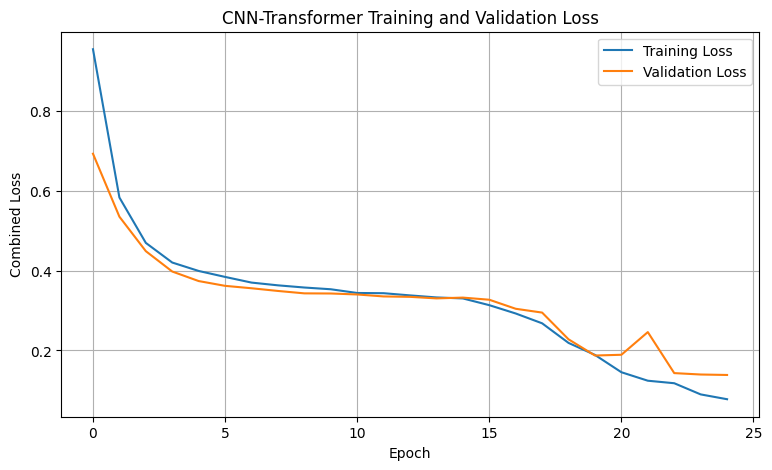

In [36]:
plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Combined Loss")
plt.title("CNN-Transformer Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## Cell 7 — Evaluate channel estimation and Doppler regression

In [37]:
predictions = model.predict(X_test, batch_size=BATCH_SIZE, verbose=1)
H_pred = predictions["channel"]
D_pred = predictions["doppler"]

channel_mse = float(np.mean((H_test - H_pred) ** 2))
channel_nmse = float(
    np.sum((H_test - H_pred) ** 2) / (np.sum(H_test ** 2) + 1e-12)
)
doppler_mae = float(mean_absolute_error(D_test, D_pred))
doppler_rmse = float(np.sqrt(mean_squared_error(D_test, D_pred)))
doppler_r2 = float(r2_score(D_test, D_pred))

print("\n===== FINAL TEST RESULTS =====")
print(f"Channel MSE:  {channel_mse:.6f}")
print(f"Channel NMSE: {channel_nmse:.6f}")
print(f"Doppler MAE:  {doppler_mae:.6f}")
print(f"Doppler RMSE: {doppler_rmse:.6f}")
print(f"Doppler R²:   {doppler_r2:.6f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step

===== FINAL TEST RESULTS =====
Channel MSE:  0.016995
Channel NMSE: 0.033990
Doppler MAE:  0.259367
Doppler RMSE: 0.359941
Doppler R²:   0.610953


## Cell 8 — Visualize channel estimation

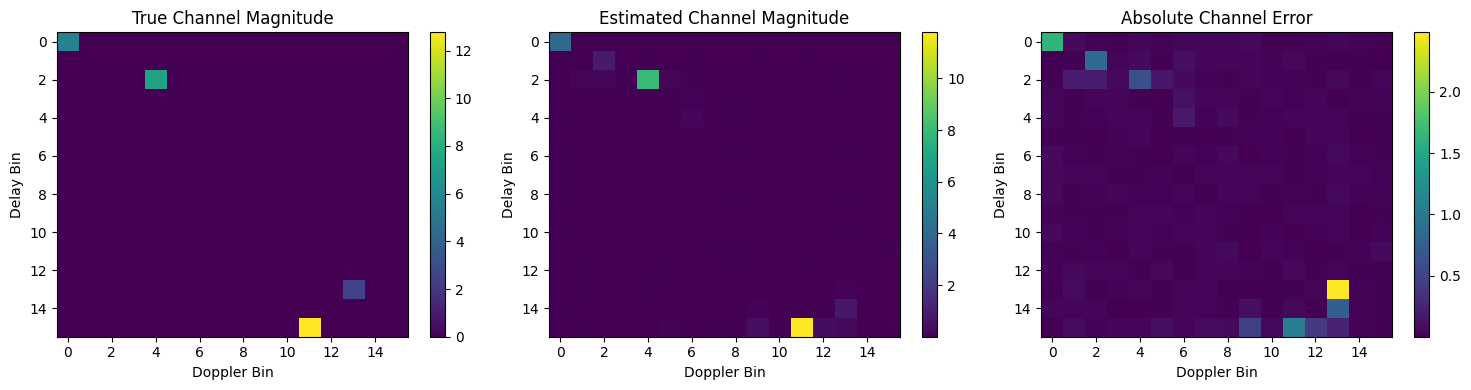

In [38]:
sample_idx = 0
H_actual_complex = H_test[sample_idx, :, :, 0] + 1j * H_test[sample_idx, :, :, 1]
H_estimated_complex = H_pred[sample_idx, :, :, 0] + 1j * H_pred[sample_idx, :, :, 1]

actual_magnitude = np.abs(H_actual_complex)
estimated_magnitude = np.abs(H_estimated_complex)
absolute_error = np.abs(H_actual_complex - H_estimated_complex)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, data, title in zip(
    axes,
    [actual_magnitude, estimated_magnitude, absolute_error],
    ["True Channel Magnitude", "Estimated Channel Magnitude", "Absolute Channel Error"]
):
    im = ax.imshow(data, aspect="auto", cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("Doppler Bin")
    ax.set_ylabel("Delay Bin")
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## Cell 9 — True versus predicted Doppler

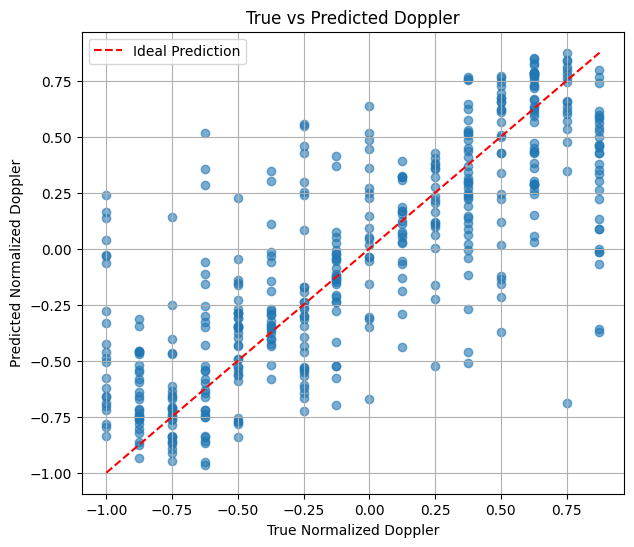

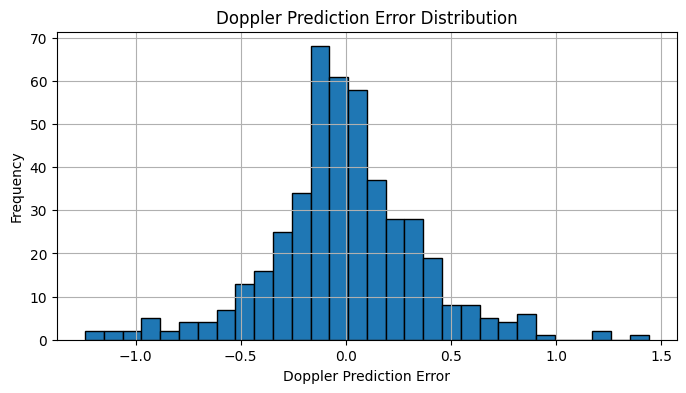

In [39]:
plt.figure(figsize=(7, 6))
plt.scatter(D_test.flatten(), D_pred.flatten(), alpha=0.6)
limits = [
    min(float(D_test.min()), float(D_pred.min())),
    max(float(D_test.max()), float(D_pred.max()))
]
plt.plot(limits, limits, "r--", label="Ideal Prediction")
plt.xlabel("True Normalized Doppler")
plt.ylabel("Predicted Normalized Doppler")
plt.title("True vs Predicted Doppler")
plt.legend()
plt.grid(True)
plt.show()

errors = (D_test - D_pred).flatten()
plt.figure(figsize=(8, 4))
plt.hist(errors, bins=30, edgecolor="black")
plt.xlabel("Doppler Prediction Error")
plt.ylabel("Frequency")
plt.title("Doppler Prediction Error Distribution")
plt.grid(True)
plt.show()

## Cell 10 — Doppler classification metrics, confusion matrix, and ROC

===== DOPPLER CLASSIFICATION RESULTS =====
Accuracy: 0.682222
Precision: 0.821622
Recall: 0.580153
F1_Score: 0.680089
ROC_AUC: 0.781123

Classification report:
              precision    recall  f1-score   support

 Low Doppler       0.58      0.82      0.68       188
High Doppler       0.82      0.58      0.68       262

    accuracy                           0.68       450
   macro avg       0.70      0.70      0.68       450
weighted avg       0.72      0.68      0.68       450



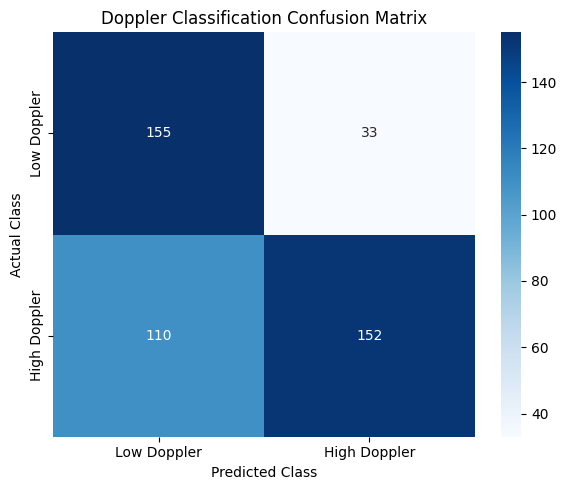

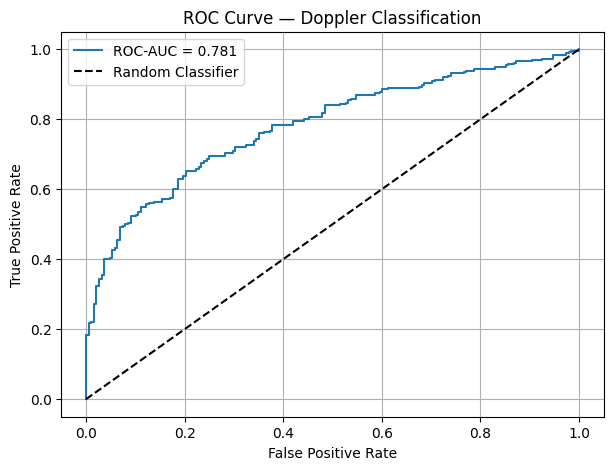

In [40]:
DOPPLER_THRESHOLD = 0.5

y_true_class = (np.abs(D_test.flatten()) >= DOPPLER_THRESHOLD).astype(int)
y_pred_class = (np.abs(D_pred.flatten()) >= DOPPLER_THRESHOLD).astype(int)
y_score = np.abs(D_pred.flatten())

classification_metrics = {
    "Accuracy": accuracy_score(y_true_class, y_pred_class),
    "Precision": precision_score(y_true_class, y_pred_class, zero_division=0),
    "Recall": recall_score(y_true_class, y_pred_class, zero_division=0),
    "F1_Score": f1_score(y_true_class, y_pred_class, zero_division=0),
    "ROC_AUC": (
        roc_auc_score(y_true_class, y_score)
        if len(np.unique(y_true_class)) == 2 else np.nan
    )
}

print("===== DOPPLER CLASSIFICATION RESULTS =====")
for name, value in classification_metrics.items():
    print(f"{name}: {value:.6f}" if pd.notna(value) else f"{name}: undefined")

print("\nClassification report:")
print(classification_report(
    y_true_class, y_pred_class,
    labels=[0, 1],
    target_names=["Low Doppler", "High Doppler"],
    zero_division=0
))

cm = confusion_matrix(y_true_class, y_pred_class, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Low Doppler", "High Doppler"],
    yticklabels=["Low Doppler", "High Doppler"]
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Doppler Classification Confusion Matrix")
plt.tight_layout()
plt.show()

if len(np.unique(y_true_class)) == 2:
    fpr, tpr, roc_thresholds = roc_curve(y_true_class, y_score)
    auc_value = roc_auc_score(y_true_class, y_score)

    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, label=f"ROC-AUC = {auc_value:.3f}")
    plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve — Doppler Classification")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("ROC-AUC unavailable: the test set contains only one class.")

## Cell 11 — Evaluate performance at different SNR levels

SNR  -5 dB | NMSE: 0.1593 | Doppler RMSE: 0.4775
SNR   0 dB | NMSE: 0.0458 | Doppler RMSE: 0.4486
SNR   5 dB | NMSE: 0.0277 | Doppler RMSE: 0.3625
SNR  10 dB | NMSE: 0.0204 | Doppler RMSE: 0.3506
SNR  15 dB | NMSE: 0.0195 | Doppler RMSE: 0.3418
SNR  20 dB | NMSE: 0.0171 | Doppler RMSE: 0.3546


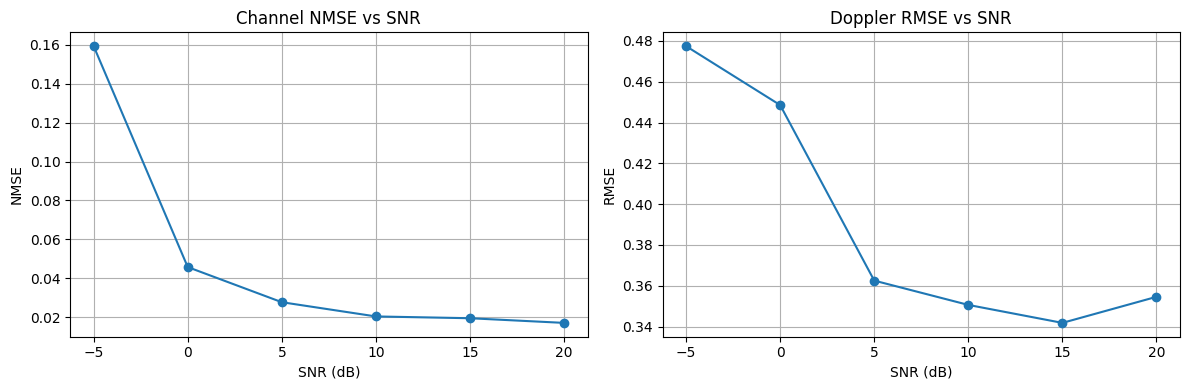

In [41]:
def evaluate_at_snr(model, snr_db, n_samples=200, seed=100):
    rng = np.random.default_rng(seed + int(snr_db * 10))
    X_eval, H_eval, D_eval = [], [], []

    for _ in range(n_samples):
        H = np.zeros((GRID_SIZE, GRID_SIZE), dtype=np.complex64)
        n_paths = int(rng.integers(1, 5))
        delays = rng.integers(0, GRID_SIZE, n_paths)
        dopplers = rng.integers(-GRID_SIZE // 2, GRID_SIZE // 2, n_paths)

        amps = (
            rng.normal(size=n_paths) + 1j * rng.normal(size=n_paths)
        ).astype(np.complex64)
        amps /= np.sqrt(np.sum(np.abs(amps) ** 2) + 1e-8)

        for delay, doppler, amp in zip(delays, dopplers, amps):
            H[delay, int(doppler % GRID_SIZE)] += amp

        H /= np.sqrt(np.mean(np.abs(H) ** 2) + 1e-8)
        dominant = np.argmax(np.abs(amps))
        d_target = np.float32(
            np.clip(dopplers[dominant] / (GRID_SIZE / 2), -1, 1)
        )

        noise_power = np.mean(np.abs(H) ** 2) / (10 ** (snr_db / 10))
        noise = np.sqrt(noise_power / 2) * (
            rng.normal(size=H.shape) + 1j * rng.normal(size=H.shape)
        )
        received = H + noise.astype(np.complex64)

        X_eval.append(np.stack([received.real, received.imag], axis=-1))
        H_eval.append(np.stack([H.real, H.imag], axis=-1))
        D_eval.append(d_target)

    X_eval = np.asarray(X_eval, dtype=np.float32)
    H_eval = np.asarray(H_eval, dtype=np.float32)
    D_eval = np.asarray(D_eval, dtype=np.float32).reshape(-1, 1)

    pred = model.predict(X_eval, verbose=0)
    nmse = np.sum((H_eval - pred["channel"]) ** 2) / (
        np.sum(H_eval ** 2) + 1e-12
    )
    rmse = np.sqrt(mean_squared_error(D_eval, pred["doppler"]))
    return float(nmse), float(rmse)


snr_results = []
for snr in [-5, 0, 5, 10, 15, 20]:
    nmse, rmse = evaluate_at_snr(model, snr)
    snr_results.append({
        "SNR_dB": snr,
        "Channel_NMSE": nmse,
        "Doppler_RMSE": rmse
    })
    print(f"SNR {snr:>3} dB | NMSE: {nmse:.4f} | Doppler RMSE: {rmse:.4f}")

snr_df = pd.DataFrame(snr_results)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(snr_df["SNR_dB"], snr_df["Channel_NMSE"], "o-")
axes[0].set_title("Channel NMSE vs SNR")
axes[0].set_xlabel("SNR (dB)")
axes[0].set_ylabel("NMSE")
axes[0].grid(True)

axes[1].plot(snr_df["SNR_dB"], snr_df["Doppler_RMSE"], "o-")
axes[1].set_title("Doppler RMSE vs SNR")
axes[1].set_xlabel("SNR (dB)")
axes[1].set_ylabel("RMSE")
axes[1].grid(True)
plt.tight_layout()
plt.show()

## Cell 12 — Save model, figures, tables, and configuration

In [42]:
os.makedirs("results/figures", exist_ok=True)
os.makedirs("results/tables", exist_ok=True)
os.makedirs("results/model", exist_ok=True)

model.save("results/model/otfs_cnn_transformer.keras")

regression_results = pd.DataFrame([{
    "Channel_MSE": channel_mse,
    "Channel_NMSE": channel_nmse,
    "Doppler_MAE": doppler_mae,
    "Doppler_RMSE": doppler_rmse,
    "Doppler_R2": doppler_r2,
    "Training_Time_Seconds": training_time
}])
regression_results.to_csv("results/tables/regression_metrics.csv", index=False)

pd.DataFrame([classification_metrics]).to_csv(
    "results/tables/classification_metrics.csv", index=False
)
snr_df.to_csv("results/tables/snr_results.csv", index=False)

config = {
    "grid_size": GRID_SIZE,
    "n_samples": N_SAMPLES,
    "snr_min_db": SNR_MIN,
    "snr_max_db": SNR_MAX,
    "epochs_requested": EPOCHS,
    "batch_size": BATCH_SIZE,
    "doppler_classification_threshold": DOPPLER_THRESHOLD,
    "random_seed": SEED
}
with open("results/model/config.json", "w") as f:
    json.dump(config, f, indent=4)

# Save training curve
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Combined Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("results/figures/training_validation_loss.png", dpi=200)
plt.close()

# Save channel heatmaps
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, data, title in zip(
    axes,
    [actual_magnitude, estimated_magnitude, absolute_error],
    ["True Channel", "Estimated Channel", "Absolute Error"]
):
    im = ax.imshow(data, aspect="auto")
    ax.set_title(title)
    ax.set_xlabel("Doppler Bin")
    ax.set_ylabel("Delay Bin")
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig("results/figures/channel_estimation.png", dpi=200)
plt.close()

# Save Doppler prediction plot
plt.figure(figsize=(7, 6))
plt.scatter(D_test.flatten(), D_pred.flatten(), alpha=0.6)
plt.plot(limits, limits, "r--", label="Ideal Prediction")
plt.xlabel("True Normalized Doppler")
plt.ylabel("Predicted Normalized Doppler")
plt.title("True vs Predicted Doppler")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("results/figures/doppler_prediction.png", dpi=200)
plt.close()

# Save confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Low", "High"], yticklabels=["Low", "High"], ax=ax
)
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")
ax.set_title("Doppler Confusion Matrix")
plt.tight_layout()
plt.savefig("results/figures/confusion_matrix.png", dpi=200)
plt.close()

if len(np.unique(y_true_class)) == 2:
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(fpr, tpr, label=f"AUC = {auc_value:.3f}")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("Doppler ROC Curve")
    ax.legend()
    ax.grid(True)
    plt.tight_layout()
    plt.savefig("results/figures/roc_curve.png", dpi=200)
    plt.close()

print("Saved model, tables, configuration, and figures.")
print("Results directory:", os.path.abspath("results"))
print("\nRegression metrics:")
print(regression_results.to_string(index=False))
print("\nClassification metrics:")
print(pd.DataFrame([classification_metrics]).to_string(index=False))

Saved model, tables, configuration, and figures.
Results directory: /content/results

Regression metrics:
 Channel_MSE  Channel_NMSE  Doppler_MAE  Doppler_RMSE  Doppler_R2  Training_Time_Seconds
    0.016995       0.03399     0.259367      0.359941    0.610953             620.461803

Classification metrics:
 Accuracy  Precision   Recall  F1_Score  ROC_AUC
 0.682222   0.821622 0.580153  0.680089 0.781123


## Cell 13 — Download all results

In [43]:
!zip -qr otfs_project_results.zip results

from google.colab import files
files.download("otfs_project_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:

import numpy as np

predictions = model.predict(X_test, batch_size=32, verbose=0)

true_doppler = np.asarray(D_test).reshape(-1)
pred_doppler = np.asarray(predictions["doppler"]).reshape(-1)

print("TRUE DOPPLER AVERAGE:", np.mean(true_doppler))
print("PREDICTED DOPPLER AVERAGE:", np.mean(pred_doppler))

print("\nTRUE DOPPLER VARIATION:", np.std(true_doppler))
print("PREDICTED DOPPLER VARIATION:", np.std(pred_doppler))

print("\nFIRST 10 RESULTS")
for i in range(10):
    print("True:", round(float(true_doppler[i]), 3),
          "| Predicted:", round(float(pred_doppler[i]), 3))


TRUE DOPPLER AVERAGE: -0.054722223
PREDICTED DOPPLER AVERAGE: -0.04864923

TRUE DOPPLER VARIATION: 0.5770723
PREDICTED DOPPLER VARIATION: 0.49678782

FIRST 10 RESULTS
True: -0.625 | Predicted: -0.256
True: -0.125 | Predicted: 0.371
True: 0.875 | Predicted: 0.765
True: -0.25 | Predicted: -0.542
True: 0.5 | Predicted: 0.339
True: 0.25 | Predicted: 0.384
True: -0.25 | Predicted: -0.531
True: 0.875 | Predicted: 0.739
True: -0.75 | Predicted: -0.842
True: -0.25 | Predicted: 0.298


In [45]:

import numpy as np

doppler = np.asarray(D_train).reshape(-1)

print("Doppler label range:", doppler.min(), "to", doppler.max())
print("Unique Doppler labels:", np.unique(doppler))
print("Number of unique labels:", len(np.unique(doppler)))

print("\nNumber of samples for each label:")
values, counts = np.unique(np.round(doppler, 4), return_counts=True)

for value, count in zip(values, counts):
    print(f"{value:7.3f}: {count}")


Doppler label range: -1.0 to 0.875
Unique Doppler labels: [-1.    -0.875 -0.75  -0.625 -0.5   -0.375 -0.25  -0.125  0.     0.125
  0.25   0.375  0.5    0.625  0.75   0.875]
Number of unique labels: 16

Number of samples for each label:
 -1.000: 129
 -0.875: 139
 -0.750: 123
 -0.625: 127
 -0.500: 143
 -0.375: 135
 -0.250: 126
 -0.125: 124
  0.000: 138
  0.125: 135
  0.250: 132
  0.375: 129
  0.500: 127
  0.625: 145
  0.750: 121
  0.875: 127


In [46]:

import numpy as np

# Inspect the training data without modifying it
X = np.asarray(X_train)
H = np.asarray(H_train)
D = np.asarray(D_train).reshape(-1)

print("Input shape:", X.shape)
print("True channel shape:", H.shape)
print("Doppler shape:", D.shape)

# Find the strongest location in each true channel
channel_power = np.sum(H**2, axis=-1)
strongest_location = np.argmax(
    channel_power.reshape(len(H), -1), axis=1
)

strongest_delay = strongest_location // GRID_SIZE
strongest_doppler_bin = strongest_location % GRID_SIZE

print("\nFirst 10 samples:")
for i in range(10):
    print(
        f"Sample {i+1}: "
        f"Target Doppler={D[i]:.3f}, "
        f"Strongest delay={strongest_delay[i]}, "
        f"Strongest Doppler bin={strongest_doppler_bin[i]}"
    )


Input shape: (2100, 16, 16, 2)
True channel shape: (2100, 16, 16, 2)
Doppler shape: (2100,)

First 10 samples:
Sample 1: Target Doppler=-0.875, Strongest delay=11, Strongest Doppler bin=9
Sample 2: Target Doppler=-0.375, Strongest delay=12, Strongest Doppler bin=13
Sample 3: Target Doppler=0.625, Strongest delay=13, Strongest Doppler bin=5
Sample 4: Target Doppler=-0.875, Strongest delay=0, Strongest Doppler bin=9
Sample 5: Target Doppler=0.375, Strongest delay=12, Strongest Doppler bin=3
Sample 6: Target Doppler=0.125, Strongest delay=0, Strongest Doppler bin=1
Sample 7: Target Doppler=-0.250, Strongest delay=6, Strongest Doppler bin=14
Sample 8: Target Doppler=-0.500, Strongest delay=2, Strongest Doppler bin=12
Sample 9: Target Doppler=-0.375, Strongest delay=11, Strongest Doppler bin=13
Sample 10: Target Doppler=-1.000, Strongest delay=9, Strongest Doppler bin=8


In [47]:

import numpy as np

H = np.asarray(H_train)
D = np.asarray(D_train).reshape(-1)

# Find the strongest location in each true channel
power = np.sum(H**2, axis=-1)
flat_index = np.argmax(power.reshape(len(H), -1), axis=1)

delay_bin = flat_index // GRID_SIZE
doppler_bin = flat_index % GRID_SIZE

# Convert Doppler grid indices to normalized signed values
mapped_doppler = np.where(
    doppler_bin >= GRID_SIZE // 2,
    doppler_bin - GRID_SIZE,
    doppler_bin
) / (GRID_SIZE // 2)

print("Target Doppler | Strongest-bin Doppler | Match")
for i in range(15):
    print(
        f"{D[i]:>7.3f}       | "
        f"{mapped_doppler[i]:>7.3f}              | "
        f"{np.isclose(D[i], mapped_doppler[i])}"
    )

print("\nOverall strongest-bin match rate:",
      round(np.mean(np.isclose(D, mapped_doppler)) * 100, 2), "%")


Target Doppler | Strongest-bin Doppler | Match
 -0.875       |  -0.875              | True
 -0.375       |  -0.375              | True
  0.625       |   0.625              | True
 -0.875       |  -0.875              | True
  0.375       |   0.375              | True
  0.125       |   0.125              | True
 -0.250       |  -0.250              | True
 -0.500       |  -0.500              | True
 -0.375       |  -0.375              | True
 -1.000       |  -1.000              | True
 -0.500       |  -0.500              | True
 -0.750       |  -0.750              | True
 -0.375       |  -0.375              | True
  0.750       |   0.750              | True
 -0.500       |  -0.500              | True

Overall strongest-bin match rate: 99.76 %


In [48]:

import numpy as np

X = np.asarray(X_train)
D = np.asarray(D_train).reshape(-1)

# Power of each noisy input grid position
input_power = np.sum(X**2, axis=-1)

# Strongest position in the noisy input
flat_index = np.argmax(
    input_power.reshape(len(X), -1), axis=1
)

input_doppler_bin = flat_index % GRID_SIZE

# Convert bin index to normalized signed Doppler
input_doppler = np.where(
    input_doppler_bin >= GRID_SIZE // 2,
    input_doppler_bin - GRID_SIZE,
    input_doppler_bin
) / (GRID_SIZE // 2)

print(
    "Noisy-input strongest-bin match rate:",
    round(np.mean(np.isclose(D, input_doppler)) * 100, 2),
    "%"
)


Noisy-input strongest-bin match rate: 96.76 %


In [49]:

import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Evaluate on the untouched test set
predictions = model.predict(X_test, batch_size=32, verbose=1)

H_pred = predictions["channel"]
D_pred = predictions["doppler"]

# Channel estimation metrics
channel_mse = np.mean((H_test - H_pred) ** 2)
channel_nmse = np.sum((H_test - H_pred) ** 2) / (
    np.sum(H_test ** 2) + 1e-12
)

# Doppler prediction metrics
D_true = np.asarray(D_test).reshape(-1)
D_est = np.asarray(D_pred).reshape(-1)

doppler_mae = mean_absolute_error(D_true, D_est)
doppler_rmse = np.sqrt(mean_squared_error(D_true, D_est))
doppler_r2 = r2_score(D_true, D_est)

print("\n===== FINAL TEST RESULTS =====")
print(f"Channel MSE:   {channel_mse:.6f}")
print(f"Channel NMSE:  {channel_nmse:.6f}")
print(f"Doppler MAE:   {doppler_mae:.6f}")
print(f"Doppler RMSE:  {doppler_rmse:.6f}")
print(f"Doppler R2:    {doppler_r2:.6f}")

print("\n===== DOPPLER DIAGNOSTICS =====")
print(f"True mean:       {np.mean(D_true):.4f}")
print(f"Predicted mean:  {np.mean(D_est):.4f}")
print(f"True std:        {np.std(D_true):.4f}")
print(f"Predicted std:   {np.std(D_est):.4f}")


15/15 ━━━━━━━━━━━━━━━━━━━━ 14s 966ms/step

===== FINAL TEST RESULTS =====
Channel MSE:   0.016995
Channel NMSE:  0.033990
Doppler MAE:   0.259367
Doppler RMSE:  0.359941
Doppler R2:    0.610953

===== DOPPLER DIAGNOSTICS =====
True mean:       -0.0547
Predicted mean:  -0.0486
True std:        0.5771
Predicted std:   0.4968
